# Random Forest: baseline y mejora (US-08)

**Issue:** #20. **Modelo de:** Rita.

Este notebook **no entrena para elegir nada**: lee las métricas ya registradas por `src/train_random_forest.py` en `results/random_forest.csv` y las explica con tablas y figuras. Solo vuelve a ajustar el modelo elegido (misma semilla, mismos datos) para dibujar la matriz de confusión y la importancia de las variables.

**Cómo se generaron los resultados** (desde la raíz del repo):

```
python -m src.train_random_forest --stage baseline
python -m src.train_random_forest --stage tune
```

**Reglas que se siguen**
- Datos: `train_70` para entrenar y `val_15` para evaluar. `test_15` no se abre (D-006, D-013).
- Preprocesado: Pipeline común con la imputación de D-011 y el encoding de D-014, ajustado solo con train.
- Métrica principal: macro-F1 en validación. Sobreajuste: accuracy(train) − accuracy(val) < 5 puntos (D-010).
- Ajuste de hiperparámetros: validación cruzada de 5 particiones sobre `train_70`; `val_15` no se usa para elegir entre configuraciones (D-010, punto 6).
- Regla de selección: entre las configuraciones con sobreajuste menor de 5 puntos en validación cruzada, las que están a menos de un error estándar de la mejor macro-F1 se consideran empatadas, y se elige la de menor sobreajuste.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix

from src.config import FEATURE_COLUMNS
from src.preprocessing import make_features_target
from src.train_random_forest import CLASSES, build_model, load_partitions

RESULTS_PATH = "results/random_forest.csv"
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"
BLUE, GRAY, ORANGE = "#2a78d6", "#c3c2b7", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
pd.set_option("display.max_colwidth", 90)

## 1. Resultados registrados

El fichero es acumulativo (`results/README.md`): cada ejecución añade filas y no se borra ninguna. Contiene tres tandas:

- **2026-11-13:** con la propuesta inicial de D-014 (29 columnas, dos para `Gender`). Sus notas dicen «D-014 (Proposed)».
- **2026-11-16, primera:** con D-014 aprobada (28 columnas, una para `Gender`) y la regla de selección inicial (mayor macro-F1 entre las admisibles).
- **2026-11-16, segunda (solo la fase de mejora):** mismos datos y mismas 60 configuraciones, con la regla de desempate por menor sobreajuste. Es la vigente.

El notebook usa solo la **última ejecución de cada fase** (baseline y mejora).

In [2]:
history = pd.read_csv(RESULTS_PATH)
history["fase"] = np.where(history["config"].str.startswith("baseline"), "baseline", "mejora")
print("Filas en el fichero:", len(history), "| semilla:", history["seed"].unique().tolist())
display(history.groupby(["fase", "run_timestamp_utc"]).size().to_frame("filas"))

latest = history.groupby("fase")["run_timestamp_utc"].transform("max")
results = history[history["run_timestamp_utc"] == latest].copy()
assert results["notes"].str.contains("Approved, 28 columns").sum() == 4  # baseline y elegido, train y val
print("Filas usadas (última ejecución de cada fase):", len(results))
results["partition"].value_counts().to_frame("filas")

Filas en el fichero: 190 | semilla: [42]


filas
fase     run_timestamp_utc          
baseline 2026-11-13T17:21:44Z      2
         2026-11-16T10:30:10Z      2
mejora   2026-11-13T17:21:46Z     62
         2026-11-16T10:30:11Z     62
         2026-11-16T10:41:19Z     62

Filas usadas (última ejecución de cada fase): 64


,filas
partition,
cv5fold,60
train_70,2
val_15,2


## 2. Baseline frente a modelo ajustado

El **baseline** usa los valores por defecto de scikit-learn (100 árboles sin límite de profundidad). El **ajustado** es la configuración elegida en la fase de mejora. La columna `gap` es accuracy(train) − accuracy(val) en puntos porcentuales: tiene que ser menor que 5.

In [3]:
final = results[results["partition"].isin(["train_70", "val_15"])].copy()
final["modelo"] = final["config"].str.split(" ").str[0]

summary = final.pivot(index="modelo", columns="partition", values=["accuracy", "macro_f1"])
summary.columns = [f"{m}_{p}" for m, p in summary.columns]
summary["gap_accuracy_puntos"] = (summary["accuracy_train_70"] - summary["accuracy_val_15"]) * 100
summary["gap_relativo_%"] = summary["gap_accuracy_puntos"] / summary["accuracy_train_70"]
summary["gap_macro_f1"] = summary["macro_f1_train_70"] - summary["macro_f1_val_15"]
summary["cumple_<5_puntos"] = summary["gap_accuracy_puntos"] < 5
summary.loc[["baseline", "tuned"]].round(4).T

modelo,baseline,tuned
accuracy_train_70,0.9683,0.5438
accuracy_val_15,0.4959,0.5248
macro_f1_train_70,0.9675,0.5321
macro_f1_val_15,0.483,0.508
gap_accuracy_puntos,47.24,1.9
gap_relativo_%,48.7865,3.4939
gap_macro_f1,0.4845,0.0241
cumple_<5_puntos,False,True


In [4]:
tuned_config = final.loc[final["modelo"] == "tuned", "config"].iloc[0]
tuned_params = json.loads(tuned_config.split(" ", 1)[1])
print("Configuración elegida:", tuned_params)

Configuración elegida: {'max_depth': 6, 'max_features': 0.5, 'min_samples_leaf': 10, 'n_estimators': 300}


### F1 por clase en validación

Muestra qué segmentos reconoce bien el modelo y cuáles confunde.

In [5]:
per_class = (final[final["partition"] == "val_15"]
             .set_index("modelo")[[f"f1_{c}" for c in CLASSES]].loc[["baseline", "tuned"]])
per_class.columns = list(CLASSES)
per_class.round(3)

,A,B,C,D
modelo,,,,
baseline,0.373,0.376,0.524,0.658
tuned,0.419,0.356,0.551,0.706


## 3. Fase de mejora: 60 configuraciones con validación cruzada

Cada punto es una configuración. En horizontal, cuánto sobreajusta (accuracy de train menos accuracy de validación cruzada); en vertical, su macro-F1 en validación cruzada. Solo son admisibles las que quedan a la izquierda de la línea de 5 puntos. Entre ellas, las que están a menos de un error estándar de la mejor se consideran empatadas (la diferencia es menor que la variación entre particiones), y se elige la de menor sobreajuste.

In [6]:
cv = results[results["partition"] == "cv5fold"].copy()
cv["params"] = cv["config"].str.split(" ", n=1).str[1].map(json.loads)
cv = pd.concat([cv.reset_index(drop=True), pd.json_normalize(cv["params"].tolist())], axis=1)
cv["gap_puntos"] = cv["notes"].str.extract(r"train - CV gap ([\d.]+)").astype(float)
cv["sd_macro_f1"] = cv["notes"].str.extract(r"sd macro-F1 ([\d.]+)").astype(float)
cv["admisible"] = cv["gap_puntos"] < 5
cv["max_depth"] = cv["max_depth"].map(lambda d: "sin límite" if pd.isna(d) else str(int(d)))

print("Configuraciones admisibles (gap < 5 puntos):", int(cv["admisible"].sum()), "de", len(cv))
top = cv[cv["admisible"]].sort_values("macro_f1", ascending=False).iloc[0]
error_estandar = top["sd_macro_f1"] / np.sqrt(5)
cv["empatada"] = cv["admisible"] & (cv["macro_f1"] >= top["macro_f1"] - error_estandar - 5e-5)  # margen por el redondeo a 4 decimales
print(f"Mejor macro-F1 admisible: {top['macro_f1']:.4f} | error estándar: {error_estandar:.4f} | "
      f"empatadas: {int(cv['empatada'].sum())}")
cols = ["max_depth", "min_samples_leaf", "max_features", "macro_f1", "sd_macro_f1", "accuracy", "gap_puntos", "empatada"]
cv[cv["admisible"]].sort_values("macro_f1", ascending=False)[cols].head(8)

Configuraciones admisibles (gap < 5 puntos): 37 de 60
Mejor macro-F1 admisible: 0.5116 | error estándar: 0.0034 | empatadas: 6


,max_depth,min_samples_leaf,max_features,macro_f1,sd_macro_f1,accuracy,gap_puntos,empatada
57,sin límite,20,0.5,0.5116,0.0077,0.5288,4.94,True
37,10,20,0.5,0.5098,0.0072,0.5275,4.68,True
47,12,20,0.5,0.5097,0.0097,0.5270,4.97,True
27,8,20,0.5,0.5090,0.0097,0.5267,3.74,True
11,6,1,0.5,0.5083,0.0097,0.5224,3.75,True
15,6,10,0.5,0.5082,0.0086,0.5222,3.01,True
13,6,5,0.5,0.5075,0.0083,0.5219,3.47,False
56,sin límite,20,sqrt,0.5065,0.0048,0.5258,3.79,False


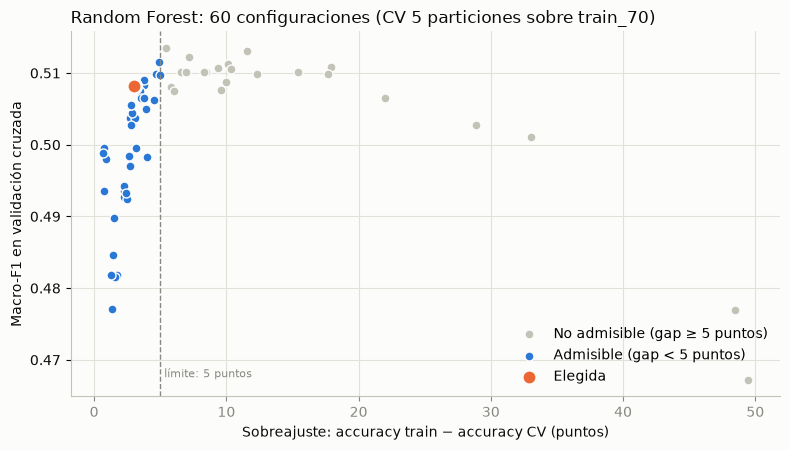

In [7]:
is_selected = cv["params"].map(lambda p: p == tuned_params)
fig, ax = plt.subplots(figsize=(8, 4.6))
for ok, color, label in [(False, GRAY, "No admisible (gap ≥ 5 puntos)"), (True, BLUE, "Admisible (gap < 5 puntos)")]:
    sub = cv[(cv["admisible"] == ok) & ~is_selected]
    ax.scatter(sub["gap_puntos"], sub["macro_f1"], s=42, color=color, edgecolor=SURFACE, linewidth=1, label=label)
sel = cv[is_selected].iloc[0]
ax.scatter(sel["gap_puntos"], sel["macro_f1"], s=110, color=ORANGE, edgecolor=SURFACE, linewidth=2, label="Elegida", zorder=3)
ax.axvline(5, color=MUTED, linewidth=1, linestyle="--")
ax.text(5.3, cv["macro_f1"].min(), "límite: 5 puntos", color=MUTED, fontsize=8, va="bottom")
ax.set_xlabel("Sobreajuste: accuracy train − accuracy CV (puntos)")
ax.set_ylabel("Macro-F1 en validación cruzada")
ax.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Random Forest: 60 configuraciones (CV 5 particiones sobre train_70)", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "rf_tuning_cv.png"), dpi=120, facecolor=SURFACE)
plt.show()

### ¿Qué hiperparámetro controla el sobreajuste?

Media del sobreajuste (puntos) según profundidad máxima y mínimo de muestras por hoja. Cuanto más arriba y a la izquierda (árboles profundos con hojas pequeñas), más memoriza el modelo.

In [8]:
depth_order = ["4", "6", "8", "10", "12", "sin límite"]
gap_table = cv.pivot_table(index="max_depth", columns="min_samples_leaf", values="gap_puntos", aggfunc="mean").loc[depth_order]
gap_table.round(1)

min_samples_leaf,1,5,10,20,40
max_depth,,,,,
4,1.2,1.2,1.2,1.0,1.0
6,3.9,3.3,2.9,2.5,2.1
8,9.8,6.5,5.0,3.4,2.5
10,20.0,10.4,7.2,4.1,2.6
12,31.0,12.9,8.0,4.5,2.6
sin límite,48.9,14.7,8.4,4.4,2.6


In [9]:
f1_table = cv.pivot_table(index="max_depth", columns="min_samples_leaf", values="macro_f1", aggfunc="mean").loc[depth_order]
f1_table.round(3)

min_samples_leaf,1,5,10,20,40
max_depth,,,,,
4,0.491,0.491,0.490,0.490,0.485
6,0.503,0.503,0.503,0.499,0.494
8,0.509,0.510,0.510,0.506,0.498
10,0.509,0.510,0.509,0.508,0.499
12,0.502,0.510,0.510,0.507,0.499
sin límite,0.472,0.512,0.509,0.509,0.499


## 4. Modelo elegido: en qué se equivoca

Se vuelve a ajustar la configuración elegida sobre `train_70` (misma semilla) y se comprueba que reproduce las métricas registradas antes de dibujar nada.

In [10]:
frames = load_partitions()
X_train, y_train = make_features_target(frames["train_70"])
X_val, y_val = make_features_target(frames["val_15"])
model = build_model(**tuned_params).fit(X_train, y_train)
pred_val = model.predict(X_val)

recorded = final[(final["modelo"] == "tuned") & (final["partition"] == "val_15")]["accuracy"].iloc[0]
refit = (pred_val == y_val).mean()
assert abs(refit - recorded) < 1e-4, (refit, recorded)
print(f"Accuracy en val_15: {refit:.4f} (coincide con la registrada: {recorded:.4f})")

train_70: 5647 rows, SHA-256 (LF) 58da50146ebd... OK
val_15: 1210 rows, SHA-256 (LF) f7243496ce9a... OK
No ID overlap between train_70 and val_15.


Accuracy en val_15: 0.5248 (coincide con la registrada: 0.5248)


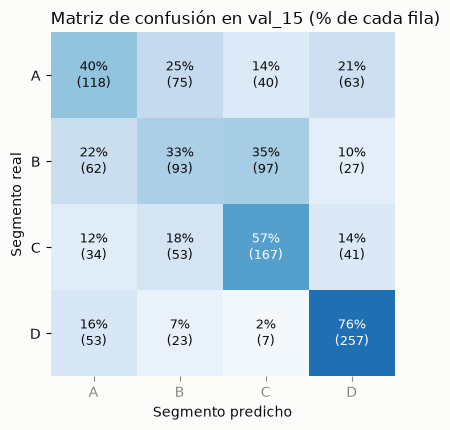

,pred A,pred B,pred C,pred D
real A,39.9,25.3,13.5,21.3
real B,22.2,33.3,34.8,9.7
real C,11.5,18.0,56.6,13.9
real D,15.6,6.8,2.1,75.6


In [11]:
cm = confusion_matrix(y_val, pred_val, labels=list(CLASSES))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm_pct[i, j]:.0f}%\n({cm[i, j]})", ha="center", va="center", fontsize=9,
                color="#ffffff" if cm_pct[i, j] > 50 else INK)
ax.set_xticks(range(4), CLASSES); ax.set_yticks(range(4), CLASSES)
ax.set_xlabel("Segmento predicho"); ax.set_ylabel("Segmento real")
ax.spines[:].set_visible(False)
ax.set_title("Matriz de confusión en val_15 (% de cada fila)", loc="left", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "rf_confusion_matrix_val.png"), dpi=120, facecolor=SURFACE)
plt.show()

pd.DataFrame(cm_pct, index=[f"real {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES]).round(1)

### Importancia de las variables

La importancia de un Random Forest mide cuánto reduce cada variable la impureza de los árboles. Las columnas one-hot se suman por variable original para poder compararlas. Es una medida **del modelo**, no una prueba de causa.

In [12]:
names = model.named_steps["preprocessing"].get_feature_names_out()
importances = model.named_steps["model"].feature_importances_


def source_variable(name):
    if name.startswith("missingindicator_"):
        return name.replace("missingindicator_", "") + " (indicador de nulo)"
    return next(col for col in sorted(FEATURE_COLUMNS, key=len, reverse=True) if name.startswith(col))


by_var = (pd.Series(importances, index=names).groupby(source_variable).sum().sort_values(ascending=False) * 100)
print("Columnas tras el preprocesado:", len(names))
by_var.round(1).to_frame("importancia_%")

Columnas tras el preprocesado: 28


,importancia_%
Age,34.6
Profession,30.3
Spending_Score,16.8
Graduated,5.4
Family_Size,3.7
Var_1,2.9
Ever_Married,2.8
Work_Experience,1.8
Gender,1.2
Work_Experience (indicador de nulo),0.3


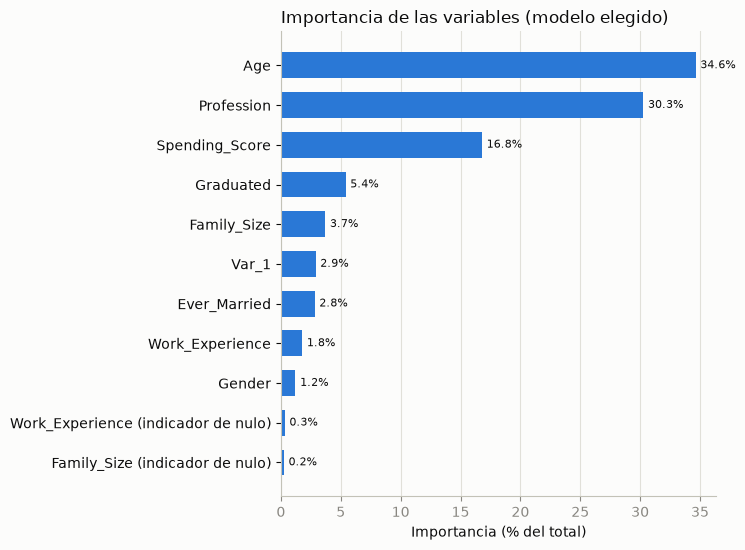

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 0.4 * len(by_var) + 1.2))
ax.barh(by_var.index[::-1], by_var.values[::-1], color=BLUE, height=0.65)
for y, v in enumerate(by_var.values[::-1]):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", fontsize=8, color=INK)
ax.set_xlabel("Importancia (% del total)")
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Importancia de las variables (modelo elegido)", loc="left", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "rf_feature_importance.png"), dpi=120, facecolor=SURFACE)
plt.show()

### Comparación con la tanda anterior (29 columnas)

Solo como referencia: métricas de todas las tandas registradas. Entre la primera y la segunda cambia el encoding de `Gender` (dos columnas frente a una); entre la segunda y la tercera, solo la regla de selección.

In [14]:
hist = history[history["partition"].isin(["train_70", "val_15"])].copy()
hist["modelo"] = hist["config"].str.split(" ").str[0]
hist["tanda"] = np.select(
    [hist["notes"].str.contains("Proposed"), hist["notes"].str.contains("within one standard error")],
    ["1. 29 columnas", "3. 28 columnas, con desempate (vigente)"],
    default="2. 28 columnas",
)
comp = hist.pivot(index=["modelo", "tanda"], columns="partition", values=["accuracy", "macro_f1"])
comp.columns = [f"{m}_{p}" for m, p in comp.columns]
comp["gap_accuracy_puntos"] = (comp["accuracy_train_70"] - comp["accuracy_val_15"]) * 100
display(comp.round(4))
hist[hist["modelo"] == "tuned"].drop_duplicates("tanda").set_index("tanda")["config"].to_frame("configuración elegida")

accuracy_train_70  \
modelo   tanda                                                        
baseline 1. 29 columnas                                      0.9683   
         2. 28 columnas                                      0.9683   
tuned    1. 29 columnas                                      0.5628   
         2. 28 columnas                                      0.5792   
         3. 28 columnas, con desempate (vigente)             0.5438   

                                                  accuracy_val_15  \
modelo   tanda                                                      
baseline 1. 29 columnas                                    0.4983   
         2. 28 columnas                                    0.4959   
tuned    1. 29 columnas                                    0.5421   
         2. 28 columnas                                    0.5314   
         3. 28 columnas, con desempate (vigente)           0.5248   

                                                  macro_f1_train_70  \
modelo   tanda                                                        
baseline 1. 29 columnas                                      0.9675   
         2. 28 columnas                                      0.9675   
tuned    1. 29 columnas                                      0.5442   
         2. 28 columnas                                      0.5656   
         3. 28 columnas, con desempate (vigente)             0.5321   

                                                  macro_f1_val_15  \
modelo   tanda                                                      
baseline 1. 29 columnas                                    0.4849   
         2. 28 columnas                                    0.4830   
tuned    1. 29 columnas                                    0.5197   
         2. 28 columnas                                    0.5102   
         3. 28 columnas, con desempate (vigente)           0.5080   

                                                  gap_accuracy_puntos  
modelo   tanda                                                         
baseline 1. 29 columnas                                         47.00  
         2. 28 columnas                                         47.24  
tuned    1. 29 columnas                                          2.07  
         2. 28 columnas                                          4.78  
         3. 28 columnas, con desempate (vigente)                 1.90

,configuración elegida
tanda,
1. 29 columnas,"tuned {""max_depth"": 12, ""max_features"": ""sqrt"", ""min_samples_leaf"": 20, ""n_estimators""..."
2. 28 columnas,"tuned {""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 20, ""n_estimators"":..."
"3. 28 columnas, con desempate (vigente)","tuned {""max_depth"": 6, ""max_features"": 0.5, ""min_samples_leaf"": 10, ""n_estimators"": 300}"


## 5. Conclusiones

Todas las cifras salen de la última ejecución registrada en `results/random_forest.csv` (2026-11-16, D-014 aprobada, 28 columnas, regla con desempate) y de las tablas de este notebook.

**Baseline**
- Con los valores por defecto, el Random Forest memoriza los datos de entrenamiento: accuracy de 96,8 % en train y 49,6 % en validación. La diferencia es de **47,2 puntos**, muy lejos del límite de 5. No cumple el criterio de D-010.
- Macro-F1 en validación: 0,483.

**Modelo ajustado**
- Configuración elegida: 300 árboles, `max_depth=6`, `min_samples_leaf=10`, `max_features=0.5`, semilla 42.
- Accuracy de 54,4 % en train y **52,5 % en validación**: diferencia de **1,90 puntos** (3,5 % en relativo). **Cumple** el límite de sobreajuste con margen.
- Macro-F1 en validación: **0,508**, frente a 0,483 del baseline. Mejora el baseline en las dos métricas y deja de sobreajustar.

**Cómo se eligió (regla de selección)**
- De las 60 configuraciones, 37 cumplen el límite de 5 puntos en validación cruzada.
- La mejor de ellas tiene macro-F1 de 0,5116, con un error estándar de 0,0034. Seis configuraciones quedan dentro de ese margen (0,508 a 0,512): la diferencia entre ellas es menor que la variación entre particiones, así que se consideran empatadas.
- Entre las empatadas se elige la de **menor sobreajuste**: 3,01 puntos en validación cruzada, frente a 4,94 de la que tiene más macro-F1.
- La elegida es la última que entra en el empate: su macro-F1 (0,5082) coincide con el umbral a cuatro decimales. Si quedara fuera, la regla elegiría `max_depth=8`, `min_samples_leaf=20` (3,74 puntos).
- Todo se decide con la validación cruzada sobre `train_70`; `val_15` no interviene.

**Por qué se añadió el desempate**
- Con la regla inicial (mayor macro-F1 entre las admisibles) ganaba una configuración sin límite de profundidad que cumplía el criterio por muy poco: 4,94 puntos en validación cruzada y 4,78 en `val_15`.
- La ventaja de esa configuración era de 0,002 en macro-F1, menos que el error estándar. No compensa quedarse al borde del límite.
- El cambio de regla lo decidió Rita el 2026-11-16, después de ver ese resultado. Las dos ejecuciones están en el fichero de resultados y en la tabla comparativa.
- Coste en `val_15` respecto a la regla inicial: macro-F1 0,510 → 0,508 y accuracy 53,1 % → 52,5 %. A cambio, la diferencia baja de 4,78 a 1,90 puntos.

**Qué reduce el sobreajuste**
- `min_samples_leaf`: obliga a que cada hoja agrupe un mínimo de clientes, así el árbol no puede aprenderse casos sueltos. Sin límite de profundidad, la diferencia media baja de 48,9 puntos (hojas de 1) a 4,4 (hojas de 20).
- `max_depth`: con profundidad 6 la diferencia media queda entre 2 y 4 puntos con cualquier tamaño de hoja. Con profundidad 4 baja a 1 punto, pero el modelo se queda corto: macro-F1 de 0,49 frente a 0,51.

**El modelo ha llegado a su techo con estas variables**
- Las configuraciones con más macro-F1 (hasta 0,514) no son admisibles porque sobreajustan, y la ganancia es mínima.
- Es coherente con D-009: hay clientes con perfil idéntico en segmentos distintos, y eso limita lo que cualquier modelo puede acertar.

**En qué se equivoca**
- **D** es el segmento que mejor reconoce: acierta el 76 % (F1 0,706).
- **C**: acierta el 57 % (F1 0,551). **A**: acierta el 40 % (F1 0,419).
- **B** es el punto débil: solo acierta el 33 % (F1 0,356), por debajo del baseline (0,376). El 35 % de los B se predicen como C y el 22 % como A. Encaja con el EDA: B y C se parecen en gasto y en estado civil.

**Qué variables usa**
- `Age` (34,6 %), `Profession` (30,3 %) y `Spending_Score` (16,8 %) suman el 82 % de la importancia.
- `Ever_Married` pesa poco (2,8 %) aunque en el EDA separaba bien D. Una explicación posible es que comparte información con `Spending_Score` (todos los no casados tienen gasto Low), y el modelo reparte la importancia entre las dos.
- Los indicadores de nulo casi no aportan (0,5 % entre los dos).
- Esta importancia tiende a favorecer a las variables numéricas y a las que tienen muchas categorías, así que es orientativa.

**Efecto del cambio de encoding (29 → 28 columnas)**
- La única diferencia es `Gender`: una columna en lugar de dos. La información es la misma.
- El baseline apenas cambia (macro-F1 en validación 0,485 → 0,483).
- Con la regla inicial, la configuración elegida sí cambió, porque las mejores estaban empatadas y una diferencia mínima altera el orden. Eso mostró que la elección era poco estable y motivó el desempate.

**Para US-11**
- Configuración fijada: `{"n_estimators": 300, "max_depth": 6, "min_samples_leaf": 10, "max_features": 0.5}`, semilla `RANDOM_STATE = 42`.
- El preprocesado usa D-011 y D-014, las dos aprobadas: 28 columnas.
- `test_15` no se ha usado.
